# Phase 6: Machine Learning Model Development

## Session 8: Baseline + Logistic Regression

**Objective:** Train classification models and identify the best-performing model.

**Leakage prevention:** Exclude `duration` because it is known only after the call.

## 1. Imports and Reproducibility

In [1]:
# ==========================================
# 1. IMPORTS AND REPRODUCIBILITY
# ==========================================

import sys
import warnings
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Suppress unnecessary warnings
warnings.filterwarnings("ignore")

# Project paths
CURRENT_DIR = Path.cwd()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_data.csv"
IMAGE_DIR = PROJECT_ROOT / "images" / "model_development"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("=" * 55)
print("PHASE 6 - MODEL DEVELOPMENT")
print("=" * 55)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)

print("\nProject root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Image directory:", IMAGE_DIR)
print("Random state:", RANDOM_STATE)

print("\nSetup completed successfully.")

PHASE 6 - MODEL DEVELOPMENT
Python: 3.11.13
NumPy: 2.4.6
Pandas: 3.1.0
Scikit-learn: 1.9.1
Imbalanced-learn: 0.14.2

Project root: /Users/ajeetsherkar/Bank-Marketing-ML-PBL
Dataset path: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/data/processed/cleaned_data.csv
Image directory: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/model_development
Random state: 42

Setup completed successfully.


## 2. Load and Validate Dataset

In [2]:
# ==========================================
# 2. LOAD AND VALIDATE DATASET
# ==========================================

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

# Display dataset information
print("=" * 55)
print("DATASET VALIDATION")
print("=" * 55)

print("\nDataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nTarget distribution:")
display(df["y"].value_counts())

print("\nTarget distribution (%):")
display(
    (df["y"].value_counts(normalize=True) * 100)
    .round(2)
)

# Data quality checks
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Assertions
assert df.shape == (4521, 17), "Unexpected dataset dimensions"
assert "y" in df.columns, "Target column missing"
assert df["y"].isin(["yes", "no"]).all(), "Unexpected target labels"
assert df.isnull().sum().sum() == 0, "Missing values detected"
assert not df.duplicated().any(), "Duplicate rows detected"

print("\nAll dataset validation checks passed.")

DATASET VALIDATION

Dataset shape: (4521, 17)

First five rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 826.8 KB

Target distribution:


y
no     4000
yes     521
Name: count, dtype: int64


Target distribution (%):


y
no     88.48
yes    11.52
Name: proportion, dtype: float64


Missing values: 0
Duplicate rows: 0

All dataset validation checks passed.


## 3. Separate Features and Target

In [4]:
# ==========================================
# 3. SEPARATE FEATURES AND TARGET
# ==========================================

# Separate target from predictive features
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("=" * 55)
print("FEATURE-TARGET SEPARATION")
print("=" * 55)

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "no", 1: "yes"}))

print("\nTarget proportions:")
display(
    (y.value_counts(normalize=True) * 100)
    .round(2)
)

# Validation checks
assert "y" not in X.columns
assert "duration" not in X.columns
assert y.isin([0, 1]).all()
assert len(X) == len(y)
assert len(numerical_features) == 6
assert len(categorical_features) == 9
assert len(numerical_features) + len(categorical_features) == 15

print("\nFeature-target separation completed successfully.")


FEATURE-TARGET SEPARATION

Feature matrix shape: (4521, 15)
Target vector shape: (4521,)

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Target distribution:


y
no     4000
yes     521
Name: count, dtype: int64


Target proportions:


y
0    88.48
1    11.52
Name: proportion, dtype: float64


Feature-target separation completed successfully.


## 4. Stratified Train-Validation Split

In [5]:
# ==========================================
# 4. STRATIFIED TRAIN-VALIDATION SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("=" * 55)
print("TRAIN-VALIDATION SPLIT")
print("=" * 55)

print("\nTraining features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining target distribution:")
display(y_train.value_counts().rename(index={0: "no", 1: "yes"}))

print("\nValidation target distribution:")
display(y_val.value_counts().rename(index={0: "no", 1: "yes"}))

print("\nTraining positive rate:",
      round(y_train.mean() * 100, 2), "%")

print("Validation positive rate:",
      round(y_val.mean() * 100, 2), "%")

# Validation checks
assert len(X_train) == 3616
assert len(X_val) == 905
assert len(y_train) == 3616
assert len(y_val) == 905

assert abs(y_train.mean() - y_val.mean()) < 0.01

assert X_train.index.intersection(X_val.index).empty

print("\nStratified split completed successfully.")

TRAIN-VALIDATION SPLIT

Training features: (3616, 15)
Validation features: (905, 15)

Training target distribution:


y
no     3199
yes     417
Name: count, dtype: int64


Validation target distribution:


y
no     801
yes    104
Name: count, dtype: int64


Training positive rate: 11.53 %
Validation positive rate: 11.49 %

Stratified split completed successfully.


## 5. Baseline Model — Dummy Classifier

In [6]:
# ==========================================
# 5. BASELINE MODEL - DUMMY CLASSIFIER
# ==========================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Initialize baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train baseline
baseline_model.fit(X_train, y_train)

# Predict validation data
baseline_predictions = baseline_model.predict(X_val)

# Predicted probabilities
baseline_probabilities = baseline_model.predict_proba(X_val)[:, 1]

# Calculate metrics
baseline_metrics = {
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(y_val, baseline_predictions),
    "Precision": precision_score(
        y_val, baseline_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, baseline_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, baseline_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, baseline_probabilities),
    "PR-AUC": average_precision_score(y_val, baseline_probabilities)
}

# Display results
baseline_results = pd.DataFrame([baseline_metrics])

print("=" * 55)
print("DUMMY CLASSIFIER BASELINE")
print("=" * 55)

display(baseline_results.round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, baseline_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        baseline_predictions,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

print("\nBaseline training and evaluation completed.")

DUMMY CLASSIFIER BASELINE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.8851,0.0,0.0,0.0,0.5,0.1149



Confusion Matrix:
[[801   0]
 [104   0]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.89      1.00      0.94       801
   Subscription       0.00      0.00      0.00       104

       accuracy                           0.89       905
      macro avg       0.44      0.50      0.47       905
   weighted avg       0.78      0.89      0.83       905


Baseline training and evaluation completed.


## 6. Logistic Regression Pipeline

In [7]:
# ==========================================
# 6. LOGISTIC REGRESSION PIPELINE
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from src.preprocessing import build_smotenc_model_pipeline

# Build Logistic Regression with SMOTENC preprocessing
logistic_model = build_smotenc_model_pipeline(
    estimator=LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
        class_weight=None
    ),
    random_state=RANDOM_STATE
)

print("=" * 55)
print("LOGISTIC REGRESSION PIPELINE")
print("=" * 55)

print("\nPipeline structure:")
for name, step in logistic_model.steps:
    print(f"- {name}: {type(step).__name__}")

print("\nPipeline created successfully.")

LOGISTIC REGRESSION PIPELINE

Pipeline structure:
- sampler: SMOTENC
- preprocessor: ColumnTransformer
- model: LogisticRegression

Pipeline created successfully.


## 7. Train Logistic Regression

In [8]:
# ==========================================
# 7. TRAIN LOGISTIC REGRESSION
# ==========================================

import time

print("=" * 55)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 55)

start_time = time.time()

# Train complete pipeline
logistic_model.fit(X_train, y_train)

training_time = time.time() - start_time

# Generate validation predictions
logistic_predictions = logistic_model.predict(X_val)

logistic_probabilities = logistic_model.predict_proba(X_val)[:, 1]

print("\nTraining completed successfully.")
print(f"Training time: {training_time:.3f} seconds")

print("\nPrediction shape:", logistic_predictions.shape)
print("Probability shape:", logistic_probabilities.shape)

print("\nFirst 10 predictions:")
print(logistic_predictions[:10])

print("\nFirst 10 predicted probabilities:")
print(np.round(logistic_probabilities[:10], 4))

# Validate outputs
assert len(logistic_predictions) == len(y_val)
assert len(logistic_probabilities) == len(y_val)
assert np.isfinite(logistic_probabilities).all()
assert ((logistic_probabilities >= 0) &
        (logistic_probabilities <= 1)).all()

print("\nLogistic Regression training and prediction checks passed.")

TRAINING LOGISTIC REGRESSION

Training completed successfully.
Training time: 0.231 seconds

Prediction shape: (905,)
Probability shape: (905,)

First 10 predictions:
[0 0 0 0 0 0 0 0 1 0]

First 10 predicted probabilities:
[0.138  0.0162 0.2369 0.024  0.2065 0.0562 0.2032 0.4984 0.5039 0.0038]

Logistic Regression training and prediction checks passed.


## 8. Evaluation and Comparison

In [9]:
# ==========================================
# 8. EVALUATION AND COMPARISON
# ==========================================

# Calculate Logistic Regression metrics
logistic_metrics = {
    "Model": "Logistic Regression + SMOTENC",
    "Accuracy": accuracy_score(y_val, logistic_predictions),
    "Precision": precision_score(
        y_val, logistic_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, logistic_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, logistic_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, logistic_probabilities),
    "PR-AUC": average_precision_score(y_val, logistic_probabilities)
}

# Combine baseline and Logistic Regression
comparison_results = pd.DataFrame([
    baseline_metrics,
    logistic_metrics
])

print("=" * 65)
print("BASELINE VS LOGISTIC REGRESSION")
print("=" * 65)

display(comparison_results.round(4))

print("\nLogistic Regression Classification Report:")
print(
    classification_report(
        y_val,
        logistic_predictions,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

# Calculate improvement over baseline
print("\nPerformance changes compared with baseline:")

for metric in ["Accuracy", "Precision", "Recall", "F1-Score",
               "ROC-AUC", "PR-AUC"]:
    improvement = (
        logistic_metrics[metric] - baseline_metrics[metric]
    )
    print(f"{metric}: {improvement:+.4f}")

print("\nEvaluation completed successfully.")

BASELINE VS LOGISTIC REGRESSION


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.8851,0.0000,0.0000,0.0000,0.500,0.1149
1,Logistic Regression + SMOTENC,0.6707,0.1891,0.5673,0.2837,0.688,0.2899



Logistic Regression Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.92      0.68      0.79       801
   Subscription       0.19      0.57      0.28       104

       accuracy                           0.67       905
      macro avg       0.56      0.63      0.53       905
   weighted avg       0.84      0.67      0.73       905


Performance changes compared with baseline:
Accuracy: -0.2144
Precision: +0.1891
Recall: +0.5673
F1-Score: +0.2837
ROC-AUC: +0.1880
PR-AUC: +0.1749

Evaluation completed successfully.


## 9. Confusion Matrix and Visualizations

LOGISTIC REGRESSION - CONFUSION MATRIX
[[548 253]
 [ 45  59]]

True Negatives: 548
False Positives: 253
False Negatives: 45
True Positives: 59


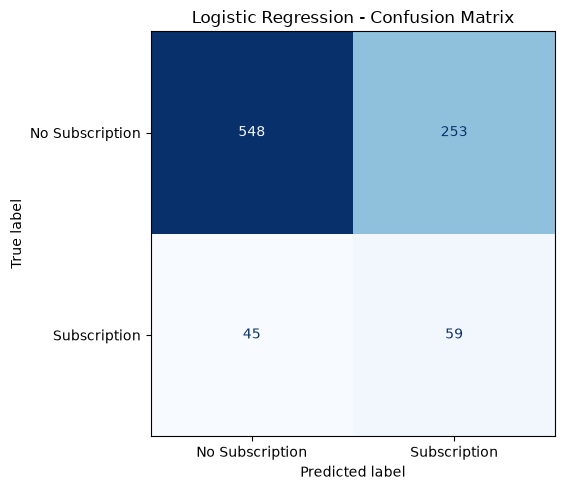

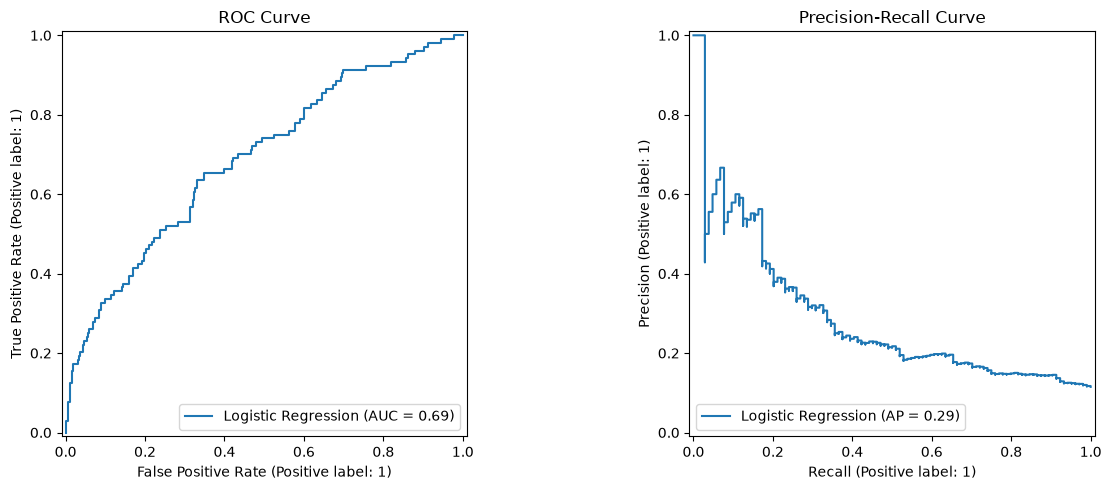


Figures saved successfully.
Image directory: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/model_development


In [10]:
# ==========================================
# 9. CONFUSION MATRIX AND VISUALIZATIONS
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_val, logistic_predictions)

tn, fp, fn, tp = cm.ravel()

print("=" * 55)
print("LOGISTIC REGRESSION - CONFUSION MATRIX")
print("=" * 55)

print(cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Subscription", "Subscription"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "01_logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot ROC curve and Precision-Recall curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_val,
    logistic_probabilities,
    ax=axes[0],
    name="Logistic Regression"
)

axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_val,
    logistic_probabilities,
    ax=axes[1],
    name="Logistic Regression"
)

axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "02_logistic_roc_pr_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigures saved successfully.")
print("Image directory:", IMAGE_DIR)

## 10. Observations and Business Insights

### Session 8 — Baseline and Logistic Regression Findings

**1. Baseline model**
- The Dummy Classifier achieved 88.51% accuracy by predicting every customer as a non-subscriber.
- Its precision, recall and F1-score were zero.
- This demonstrated that accuracy alone is misleading for this imbalanced dataset.

**2. Logistic Regression**
- Logistic Regression with SMOTENC achieved 67.07% accuracy.
- Precision: 18.91%.
- Recall: 56.73%.
- F1-score: 28.37%.
- ROC-AUC: 0.6880.
- PR-AUC: 0.2899.

**3. Confusion matrix observations**
- True Positives: 59.
- True Negatives: 548.
- False Positives: 253.
- False Negatives: 45.

**4. Business insights**
- The model identified 59 of 104 actual subscribers.
- Its recall is substantially better than the Dummy Classifier.
- High false positives may increase unnecessary campaign contact costs.
- Missed subscribers represent potential lost conversion opportunities.

**5. Conclusion**

Logistic Regression is a useful first predictive model and substantially improves subscriber identification over the majority-class baseline. However, its low precision and moderate recall indicate that further model development, cross-validation and hyperparameter tuning are necessary before selecting a final model.

**Status:** Baseline and Logistic Regression completed. Final model selection is deferred until all five algorithms have been evaluated.

## Session 9: Decision Tree and Random Forest

**Objective:** Train two tree-based classification algorithms using the existing leakage-safe SMOTENC preprocessing pipeline.

**Algorithms:**
1. Decision Tree Classifier
2. Random Forest Classifier

**Evaluation:** Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

In [11]:
# ==========================================
# SESSION 9 - TREE-BASED MODELS
# ==========================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import time

print("=" * 60)
print("SESSION 9 - DECISION TREE AND RANDOM FOREST")
print("=" * 60)

# ------------------------------------------
# 1. Create Decision Tree pipeline
# ------------------------------------------

decision_tree_pipeline = build_smotenc_model_pipeline(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    random_state=42
)

# ------------------------------------------
# 2. Create Random Forest pipeline
# ------------------------------------------

random_forest_pipeline = build_smotenc_model_pipeline(
    estimator=RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    random_state=42
)

print("\nBoth model pipelines created successfully.")

# ------------------------------------------
# 3. Train Decision Tree
# ------------------------------------------

start_time = time.time()

decision_tree_pipeline.fit(X_train, y_train)

decision_tree_training_time = time.time() - start_time

decision_tree_predictions = decision_tree_pipeline.predict(X_val)

decision_tree_probabilities = (
    decision_tree_pipeline.predict_proba(X_val)[:, 1]
)

print("\nDecision Tree training completed.")
print("Training time:", round(decision_tree_training_time, 3), "seconds")

# ------------------------------------------
# 4. Train Random Forest
# ------------------------------------------

start_time = time.time()

random_forest_pipeline.fit(X_train, y_train)

random_forest_training_time = time.time() - start_time

random_forest_predictions = random_forest_pipeline.predict(X_val)

random_forest_probabilities = (
    random_forest_pipeline.predict_proba(X_val)[:, 1]
)

print("\nRandom Forest training completed.")
print("Training time:", round(random_forest_training_time, 3), "seconds")

# ------------------------------------------
# 5. Evaluation function
# ------------------------------------------

def evaluate_model(name, y_true, predictions, probabilities):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)
    }

# ------------------------------------------
# 6. Compare both models with Logistic Regression
# ------------------------------------------

decision_tree_results = evaluate_model(
    "Decision Tree",
    y_val,
    decision_tree_predictions,
    decision_tree_probabilities
)

random_forest_results = evaluate_model(
    "Random Forest",
    y_val,
    random_forest_predictions,
    random_forest_probabilities
)

logistic_results = evaluate_model(
    "Logistic Regression + SMOTENC",
    y_val,
    logistic_predictions,
    logistic_probabilities
)

session_9_results = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    random_forest_results
])

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(
    session_9_results.round(4)
)

print("\nSession 9 model training and evaluation completed.")

SESSION 9 - DECISION TREE AND RANDOM FOREST

Both model pipelines created successfully.

Decision Tree training completed.
Training time: 0.201 seconds

Random Forest training completed.
Training time: 0.45 seconds

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression + SMOTENC,0.6707,0.1891,0.5673,0.2837,0.6880,0.2899
1,Decision Tree,0.7713,0.2275,0.4135,0.2935,0.6156,0.1615
2,Random Forest,0.8166,0.2687,0.3462,0.3025,0.6979,0.2673



Session 9 model training and evaluation completed.



DECISION TREE
[[655 146]
 [ 61  43]]
True Negatives: 655
False Positives: 146
False Negatives: 61
True Positives: 43

RANDOM FOREST
[[703  98]
 [ 68  36]]
True Negatives: 703
False Positives: 98
False Negatives: 68
True Positives: 36


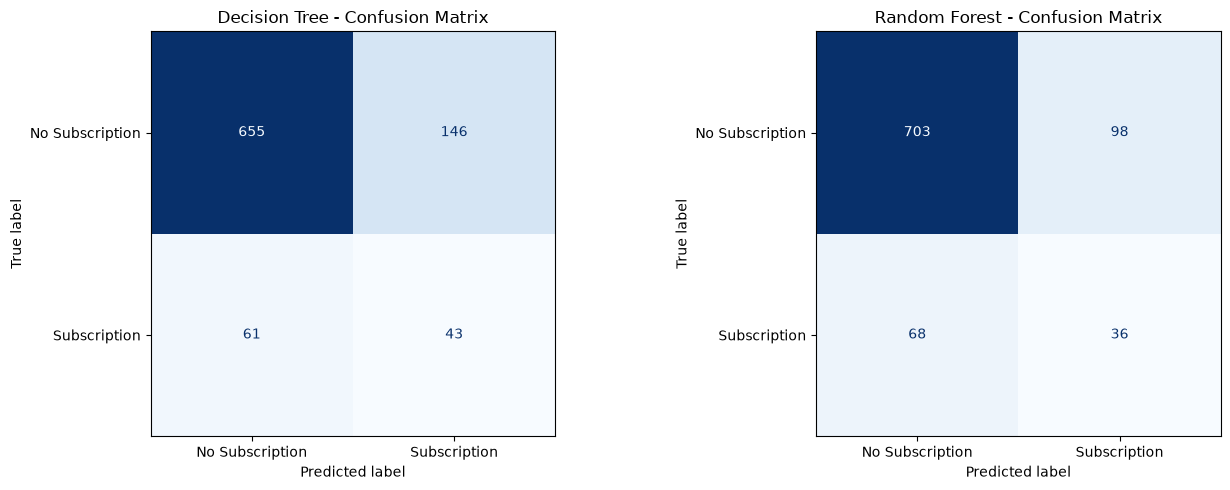


Confusion matrix figure saved successfully.


In [12]:
# ==========================================
# SESSION 9 - CONFUSION MATRICES
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

models_to_visualize = {
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, predictions) in zip(
    axes,
    models_to_visualize.items()
):

    cm = confusion_matrix(y_val, predictions)

    tn, fp, fn, tp = cm.ravel()

    print("\n" + "=" * 50)
    print(model_name.upper())
    print("=" * 50)

    print(cm)
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Subscription", "Subscription"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "03_tree_models_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix figure saved successfully.")

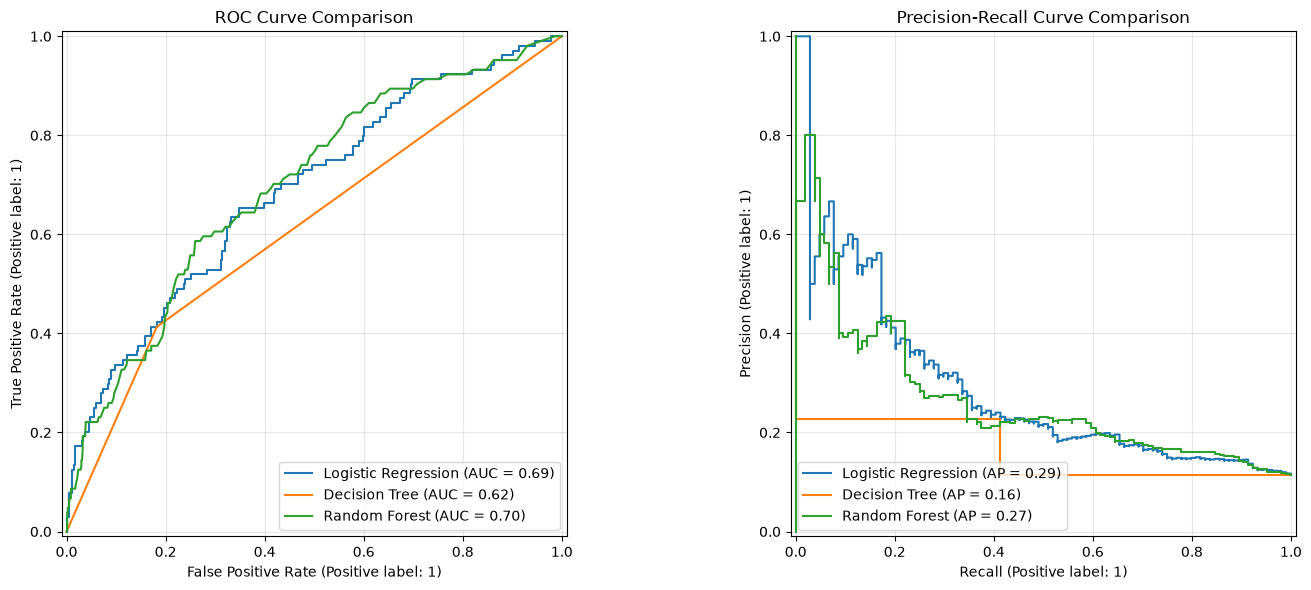

ROC and PR comparison figures saved successfully.


In [13]:
# ==========================================
# SESSION 9 - ROC AND PR CURVE COMPARISON
# ==========================================

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Model probabilities
model_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Decision Tree": decision_tree_probabilities,
    "Random Forest": random_forest_probabilities
}

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC curves
for model_name, probabilities in model_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[0]
    )

axes[0].set_title("ROC Curve Comparison")
axes[0].grid(alpha=0.3)

# Precision-Recall curves
for model_name, probabilities in model_probabilities.items():

    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[1]
    )

axes[1].set_title("Precision-Recall Curve Comparison")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "04_model_roc_pr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC and PR comparison figures saved successfully.")

RANDOM FOREST - FEATURE IMPORTANCE


,Feature,Importance
0,num__balance,0.14726
1,num__day,0.09818
2,num__age,0.08861
3,cat__contact_cellular,0.06310
4,num__campaign,0.05399
5,cat__contact_unknown,0.05163
6,num__pdays,0.05112
7,cat__loan_no,0.02512
8,cat__loan_yes,0.02448
9,cat__housing_no,0.02334


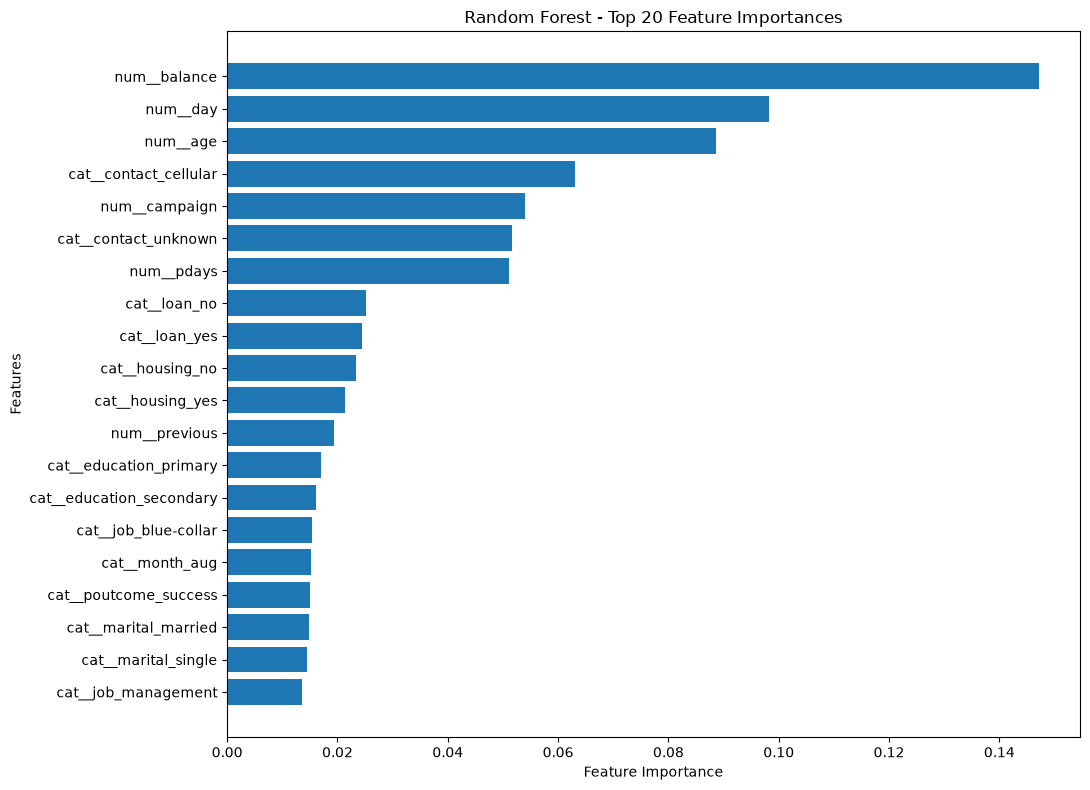


Feature importance figure saved successfully.


In [14]:
# ==========================================
# SESSION 9 - RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

# Access fitted preprocessing and Random Forest
fitted_preprocessor = random_forest_pipeline.named_steps[
    "preprocessor"
]

fitted_random_forest = random_forest_pipeline.named_steps[
    "model"
]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance
importance_values = fitted_random_forest.feature_importances_

# Create importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("RANDOM FOREST - FEATURE IMPORTANCE")
print("=" * 60)

display(feature_importance_df.head(20).round(5))

# Plot top 20 features
top_features = feature_importance_df.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 20 Feature Importances")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "05_random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFeature importance figure saved successfully.")

### Session 9 — Random Forest Feature Importance: Observations and Business Insights

**Observations**
1. Balance is the most influential feature, with an importance score of 0.14726.
2. Day and age are the second and third most important features.
3. Contact type, campaign, and previous-contact information also contribute to the model.
4. Loan and housing categories appear among the top 20 features.
5. Feature importance values represent the Random Forest model's impurity-based contribution and should not be interpreted as causal effects.

**Business Insights**
1. Customer financial information may help prioritize potential subscribers.
2. Customer age can support further analysis of different customer segments.
3. Contact type and campaign history may help improve campaign planning.
4. The bank should evaluate these patterns alongside campaign cost and customer response rates.

**Conclusion**

Balance, day, age, contact type, and campaign-related variables are among the strongest features in the current Random Forest model. These findings provide useful directions for further investigation, but they do not establish causation or determine the final feature set.

**Status:** Random Forest feature-importance analysis completed. Further model evaluation and validation are required.